# L1-c · Market features only

Standardized JISDOR features → MLP `(64, 32)` → P(UP). No text, news counts, or macro series. UP = USD/IDR rises (IDR depreciates).

Use the [shared split](../../SPLIT_PROTOCOL.md) and [ablation protocol](../../rules/ablation_protocol.md). Dependencies: NumPy, pandas, Matplotlib, scikit-learn. Outputs stay inside this notebook.

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import platform
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "deira-work/SPLIT_PROTOCOL.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
BASE = ROOT / "deira-work/preprocessing/outputs/date_delay_sensitivity__audit_only"
MODEL_ID = "L1-c"
SEEDS = [42, 123, 2026]
MAX_EPOCHS = 200
PATIENCE = 25
MLP_CONFIG = dict(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                  alpha=1e-3, batch_size=32, learning_rate_init=1e-3,
                  max_iter=1, shuffle=True, early_stopping=False)
RUN_FINAL_TEST = False  # Enable only after the experiment configurations are frozen.
BOOTSTRAP_REPEATS = 1000
BLOCK_LENGTH = 10       # Evaluated fixing observations; circular moving blocks.
BOOTSTRAP_SEED = 20261110
LABELS = ["DOWN", "UP"]
METRICS = ["mcc", "macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "log_loss", "ece_10"]
COLORS = ["#2563eb", "#ea580c", "#059669"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"{MODEL_ID} | seeds: {SEEDS} | final test enabled: {RUN_FINAL_TEST}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")

L1-c | seeds: [42, 123, 2026] | final test enabled: False
Python 3.12.3 | pandas 3.0.5 | NumPy 2.5.3 | Matplotlib 3.11.2
scikit-learn 1.9.1


## Shared data

Reuse the exact eligible dates, labels, and purges from L1-a/L1-b. Read predictors only from `feature_contract.json`. Targets, future gaps, and news availability never enter this model. Fit each scaler on its training subset only.

In [2]:
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
pipeline = json.loads((BASE / "pipeline_manifest.json").read_text())
for name, expected in pipeline["input_sha256"].items():
    assert sha256(ROOT / name) == expected, f"Source snapshot changed: {name}"
assert pipeline["config"]["alignment_mode"] == "date_delay_sensitivity"
assert pipeline["config"]["geopolitical_policy"] == "audit_only"

contract = json.loads((BASE / "feature_contract.json").read_text())
FEATURES = contract["market_features"]
assert not set(FEATURES) & set(contract["target_and_diagnostic_columns_never_predictors"])
assert not set(FEATURES) & {"n_berita", "has_news", "y", "target_date", "next_jisdor"}
assert len(FEATURES) == len(set(FEATURES))
folds = pd.read_csv(BASE / "fold_manifest.csv", parse_dates=["Date", "target_date"])
final = pd.read_csv(BASE / "final_fit_manifest.csv", parse_dates=["Date", "target_date"])
daily = pd.read_csv(BASE / "daily_market.csv", parse_dates=["Date", "target_date"])
partitions = pd.read_csv(BASE / "calendar_partitions.csv", parse_dates=["Date", "target_date"])
assert not daily.Date.duplicated().any()
assert not folds.duplicated(["fold", "role", "Date"]).any()
assert not final.Date.duplicated().any()

def take_rows(rows):
    fields = ["Date", "target_date", "y", "eligible_binary", "n_berita", "has_news",
              "target_weekday", "realized_target_gap_days", *FEATURES]
    joined = rows.merge(daily[fields], on="Date", how="left", validate="one_to_one", suffixes=("", "_daily"))
    assert len(joined) == len(rows) and joined.eligible_binary.all()
    assert joined.y.notna().all() and joined.y.isin([0, 1]).all()
    assert joined.target_date.eq(joined.target_date_daily).all()
    assert joined.y.eq(joined.y_daily).all()
    assert joined.n_berita.eq(joined.n_berita_daily).all()
    if "has_news_daily" in joined:
        assert joined.has_news.eq(joined.has_news_daily).all()
    assert np.isfinite(joined[FEATURES].to_numpy(dtype=float)).all()
    return joined.drop(columns=[c for c in joined if c.endswith("_daily")]).sort_values("Date").reset_index(drop=True)

split_summary = []
seen_validation_dates = set()
for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    assert train.target_date.max() < val.Date.min()
    assert not set(train.Date) & set(val.Date)
    assert not seen_validation_dates & set(val.Date)
    seen_validation_dates.update(val.Date)
    for role, frame in [("train", train), ("validation", val)]:
        split_summary.append({"run": f"fold_{fold_id}", "role": role, "n": len(frame),
                              "first": frame.Date.min().date(), "last": frame.Date.max().date(),
                              "down": int(frame.y.eq(0).sum()), "up": int(frame.y.eq(1).sum()),
                              "news_days": int(frame.has_news.sum())})
final_train = take_rows(final.loc[final.role.eq("train")])
test_dates = final.loc[final.role.eq("test"), "Date"]
assert final_train.target_date.max() < test_dates.min()
assert not set(final_train.Date) & set(test_dates)
display(pd.DataFrame(split_summary))
print(f"Locked test: {test_dates.min().date()} to {test_dates.max().date()} | {len(test_dates)} eligible decisions")
print("Predictors:", ", ".join(FEATURES))

,run,role,n,first,last,down,up,news_days
0,fold_1,train,453,2021-09-29,2023-08-15,193,260,65
1,fold_1,validation,158,2023-08-21,2024-04-19,64,94,21
2,fold_2,train,612,2021-09-29,2024-04-19,257,355,86
3,fold_2,validation,159,2024-04-23,2024-12-12,78,81,32
4,fold_3,train,772,2021-09-29,2024-12-12,335,437,118
5,fold_3,validation,158,2024-12-16,2025-08-26,79,79,22


Locked test: 2025-08-29 to 2026-08-31 | 235 eligible decisions
Predictors: log_return_t, return_lag1, return_lag2, return_lag3, return_lag5, volatility_5, volatility_20, ma_ratio_5, ma_ratio_20, momentum_5, momentum_10, rsi_14, input_gap_days, decision_weekday


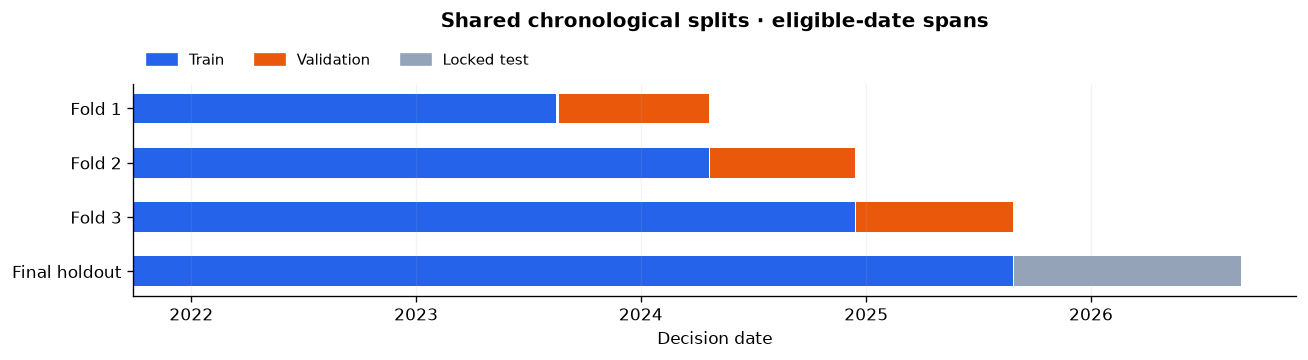

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.1))
for row, fold_id in enumerate(sorted(folds.fold.unique())):
    for role, color in [("train", COLORS[0]), ("validation", COLORS[1])]:
        dates = folds.loc[folds.fold.eq(fold_id) & folds.role.eq(role), "Date"]
        left = mdates.date2num(dates.min())
        width = mdates.date2num(dates.max()) - left + 1
        ax.barh(row, width, left=left, height=.55, color=color)
for role, color in [("train", COLORS[0]), ("test", "#94a3b8")]:
    dates = final.loc[final.role.eq(role), "Date"]
    ax.barh(3, mdates.date2num(dates.max()) - mdates.date2num(dates.min()) + 1,
            left=mdates.date2num(dates.min()), height=.55, color=color)
ax.set_yticks(range(4), ["Fold 1", "Fold 2", "Fold 3", "Final holdout"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Shared chronological splits · eligible-date spans", pad=34)
ax.set_xlabel("Decision date")
ax.legend(handles=[Patch(color=COLORS[0], label="Train"), Patch(color=COLORS[1], label="Validation"),
                   Patch(color="#94a3b8", label="Locked test")], loc="lower left", bbox_to_anchor=(0, 1.01),
          ncol=3, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()

## Training and metrics

Three fixed seeds; Adam, batch 32, learning rate 0.001, L2 alpha 0.001. Training minibatches may shuffle; split membership stays chronological. Standardization uses train only. No random internal validation split or hyperparameter search.

Select each checkpoint by validation `(MCC, macro-F1, -log loss)`, with patience 25 and at most 200 epochs. Threshold = 0.5. Report seed-mean metrics per fold; seed variation is separate from temporal sampling uncertainty. Validation selects checkpoints; final test stays locked. If enabled later, final training uses the median selected epoch across folds for each seed.

Primary: **MCC**. Also report macro-F1, balanced accuracy, accuracy, per-class precision/recall/F1, ROC-AUC, Brier, log loss, and 10-bin equal-width ECE, using the same definitions as conditions 1–2. Single-class actual subsets have undefined MCC/balanced accuracy/AUC; undefined class precision/F1 uses zero.

In [4]:
def score_binary(y, probability):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert len(y) == len(probability) and len(y)
    assert np.isin(y, [0, 1]).all() and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    pred = (probability >= .5).astype(int)
    tn, fp, fn, tp = [int(np.sum((y == actual) & (pred == predicted)))
                      for actual, predicted in [(0, 0), (0, 1), (1, 0), (1, 1)]]
    divide = lambda a, b: a / b if b else 0.
    precision_down, recall_down = divide(tn, tn + fn), divide(tn, tn + fp)
    precision_up, recall_up = divide(tp, tp + fp), divide(tp, tp + fn)
    f1_down = divide(2 * precision_down * recall_down, precision_down + recall_down)
    f1_up = divide(2 * precision_up * recall_up, precision_up + recall_up)
    both = bool(np.unique(y).size == 2)
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = divide(tp * tn - fp * fn, denominator) if both else np.nan
    n_up, n_down = int(y.sum()), int(len(y) - y.sum())
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    auc = ((ranks[y == 1].sum() - n_up * (n_up + 1) / 2) / (n_up * n_down)) if both else np.nan
    clipped = np.clip(probability, 1e-15, 1 - 1e-15)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(probability[bins == b].mean() - y[bins == b].mean())
              for b in np.unique(bins))
    return {"n": len(y), "n_down": n_down, "n_up": n_up,
            "mcc": mcc, "macro_f1": (f1_down + f1_up) / 2,
            "balanced_accuracy": (recall_down + recall_up) / 2 if both else np.nan,
            "accuracy": float((pred == y).mean()), "roc_auc": float(auc),
            "brier": float(np.mean((probability - y) ** 2)),
            "log_loss": float(-np.mean(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))),
            "ece_10": float(ece), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision_down": precision_down, "recall_down": recall_down, "f1_down": f1_down,
            "precision_up": precision_up, "recall_up": recall_up, "f1_up": f1_up}

perfect = score_binary([0, 0, 1, 1], [0., 0., 1., 1.])
constant = score_binary([0, 0, 1, 1], [.6] * 4)
assert perfect["mcc"] == perfect["macro_f1"] == perfect["roc_auc"] == 1
assert constant["mcc"] == 0 and constant["balanced_accuracy"] == constant["roc_auc"] == .5
assert np.isclose(constant["macro_f1"], 1 / 3) and np.isclose(constant["brier"], .26)
assert score_binary([0, 0, 1, 1], [1., 1., 0., 0.])["mcc"] == -1
assert np.isnan(score_binary([1, 1], [.6, .6])["roc_auc"])
print("Metric checks passed.")

Metric checks passed.


In [5]:
predictions_list, result_rows, fit_rows, history_rows, snapshots = [], [], [], [], []

def make_model(seed):
    return MLPClassifier(**MLP_CONFIG, random_state=int(seed))

def train_model(train, validation, seed, run, fixed_epochs=None):
    start = time.perf_counter()
    scaler = StandardScaler().fit(train[FEATURES])
    assert scaler.n_samples_seen_ == len(train)
    assert np.allclose(scaler.mean_, train[FEATURES].mean().to_numpy())
    x_train, y_train = scaler.transform(train[FEATURES]), train.y.to_numpy(dtype=int)
    x_val = scaler.transform(validation[FEATURES]) if validation is not None else None
    model, best_model, best_key, best_epoch, stale = make_model(seed), None, None, 0, 0
    limit = int(fixed_epochs) if fixed_epochs is not None else MAX_EPOCHS
    with threadpool_limits(limits=1):
        for epoch in range(1, limit + 1):
            model.partial_fit(x_train, y_train, classes=np.array([0, 1]))
            if validation is None:
                continue
            val_probability = model.predict_proba(x_val)[:, 1]
            score = score_binary(validation.y, val_probability)
            train_loss = score_binary(y_train, model.predict_proba(x_train)[:, 1])["log_loss"]
            history_rows.append({"run": run, "seed": seed, "epoch": epoch,
                                 "train_log_loss": train_loss, "val_log_loss": score["log_loss"],
                                 "val_mcc": score["mcc"], "val_macro_f1": score["macro_f1"]})
            key = (score["mcc"], score["macro_f1"], -score["log_loss"])
            if best_key is None or key > best_key:
                best_model, best_key, best_epoch, stale = copy.deepcopy(model), key, epoch, 0
            else:
                stale += 1
            if stale >= PATIENCE:
                break
    if validation is None:
        best_model, best_epoch = model, limit
    return scaler, best_model, best_epoch, epoch, (time.perf_counter() - start) * 1000

def evaluate_run(run, train, evaluation, role, fixed_epoch_by_seed=None):
    for seed in SEEDS:
        fixed_epochs = None if fixed_epoch_by_seed is None else fixed_epoch_by_seed[seed]
        scaler, model, best_epoch, epochs_run, fit_ms = train_model(
            train, evaluation if fixed_epochs is None else None, seed, run, fixed_epochs)
        start = time.perf_counter()
        with threadpool_limits(limits=1):
            probability = model.predict_proba(scaler.transform(evaluation[FEATURES]))[:, 1]
        predict_ms = (time.perf_counter() - start) * 1000
        parameter_count = sum(a.size for a in [*model.coefs_, *model.intercepts_])
        scored = score_binary(evaluation.y, probability)
        result_rows.append({"run": run, "role": role, "seed": seed, **scored})
        fit_rows.append({"run": run, "seed": seed, "train_n": len(train), "feature_count": len(FEATURES),
                         "train_up": int(train.y.eq(1).sum()), "best_epoch": best_epoch, "epochs_run": epochs_run,
                         "fit_ms": fit_ms, "predict_ms": predict_ms, "trainable_parameters": parameter_count})
        columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days"]
        output = evaluation[columns].copy()
        output["run"], output["role"], output["model_id"], output["training_seed"] = run, role, MODEL_ID, seed
        output["p_up"], output["y_pred"] = probability, (probability >= .5).astype(int)
        predictions_list.append(output)
        # Keep the selected weights/scaler in the notebook's result bundle.
        snapshot = {"run": run, "seed": seed, "features": FEATURES, "best_epoch": best_epoch,
                    "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
                    "coefs": [a.tolist() for a in model.coefs_], "intercepts": [a.tolist() for a in model.intercepts_],
                    "classes": model.classes_.tolist(), "activation": "relu", "output_activation": "logistic"}
        z = (evaluation[FEATURES].to_numpy(dtype=float) - scaler.mean_) / scaler.scale_
        for weights, bias in zip(model.coefs_[:-1], model.intercepts_[:-1]):
            z = np.maximum(0., z @ weights + bias)
        logits = (z @ model.coefs_[-1] + model.intercepts_[-1]).ravel()
        assert np.allclose(1 / (1 + np.exp(-np.clip(logits, -700, 700))), probability)
        snapshots.append(snapshot)
        print(f"{run} seed={seed}: best epoch {best_epoch}, MCC={scored['mcc']:.4f}")

for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    evaluate_run(f"fold_{fold_id}", train, val, "validation")

if RUN_FINAL_TEST:
    fixed_epoch_by_seed = {seed: int(np.median([r["best_epoch"] for r in fit_rows if r["seed"] == seed])) for seed in SEEDS}
    evaluate_run("final_test", final_train, take_rows(final.loc[final.role.eq("test")]), "test", fixed_epoch_by_seed)

predictions = pd.concat(predictions_list, ignore_index=True)
seed_results, fits, history = pd.DataFrame(result_rows), pd.DataFrame(fit_rows), pd.DataFrame(history_rows)
assert not predictions.duplicated(["role", "training_seed", "Date"]).any()
for seed in SEEDS:
    assert len(predictions.loc[predictions.role.eq("validation") & predictions.training_seed.eq(seed)]) == len(seen_validation_dates)
numeric = [c for c in seed_results.select_dtypes(include="number") if c != "seed"]
results = seed_results.groupby(["run", "role"], sort=False)[numeric].mean().reset_index()
for field in ["n", "n_down", "n_up"]:
    results[field] = results[field].astype(int)
seed_std = seed_results.groupby("run", sort=False)[METRICS].std(ddof=1)
validation_results = results.loc[results.role.eq("validation"), METRICS]
display(fits.round(3))
display(seed_results[["run", "seed", "n", *METRICS]].round(4))
display(results[["run", "role", "n", *METRICS]].round(4))
display(seed_std.rename_axis("run").round(4))
display(pd.DataFrame({"mean_validation": validation_results.mean(),
                      "std_across_folds": validation_results.std(ddof=1)}).round(4))
print("n counts unique dates; fold metrics average individual-seed scores, without ensembling.")
print("Final test scored." if RUN_FINAL_TEST else "Final-test scoring remains locked.")

fold_1 seed=42: best epoch 1, MCC=0.0388
fold_1 seed=123: best epoch 2, MCC=0.1286
fold_1 seed=2026: best epoch 11, MCC=0.1319
fold_2 seed=42: best epoch 24, MCC=0.1146
fold_2 seed=123: best epoch 11, MCC=0.1770
fold_2 seed=2026: best epoch 17, MCC=0.2929
fold_3 seed=42: best epoch 2, MCC=0.0275
fold_3 seed=123: best epoch 1, MCC=0.0734
fold_3 seed=2026: best epoch 5, MCC=0.0275


,run,seed,train_n,feature_count,train_up,best_epoch,epochs_run,fit_ms,predict_ms,trainable_parameters
0,fold_1,42,453,14,260,1,26,251.312,5.885,3073
1,fold_1,123,453,14,260,2,27,125.140,5.876,3073
2,fold_1,2026,453,14,260,11,36,165.236,5.787,3073
3,fold_2,42,612,14,355,24,49,267.815,5.842,3073
4,fold_2,123,612,14,355,11,36,198.230,5.745,3073
5,fold_2,2026,612,14,355,17,42,238.132,5.694,3073
6,fold_3,42,772,14,437,2,27,179.612,6.252,3073
7,fold_3,123,772,14,437,1,26,194.428,6.058,3073
8,fold_3,2026,772,14,437,5,30,213.266,6.289,3073


,run,seed,n,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
0,fold_1,42,158,0.0388,0.5119,0.5180,0.5570,0.5372,0.2441,0.6829,0.0675
1,fold_1,123,158,0.1286,0.4852,0.5384,0.6139,0.5076,0.2434,0.6796,0.0899
2,fold_1,2026,158,0.1319,0.5647,0.5645,0.5886,0.5519,0.2438,0.6866,0.1149
3,fold_2,42,159,0.1146,0.5164,0.5484,0.5535,0.5795,0.2612,0.7299,0.1266
4,fold_2,123,159,0.1770,0.5401,0.5734,0.5786,0.5693,0.2574,0.7142,0.0829
5,fold_2,2026,159,0.2929,0.6143,0.6311,0.6352,0.6295,0.2397,0.6755,0.1091
6,fold_3,42,158,0.0275,0.4931,0.5127,0.5127,0.5084,0.2514,0.6963,0.0523
7,fold_3,123,158,0.0734,0.4996,0.5316,0.5316,0.5041,0.2564,0.7059,0.0689
8,fold_3,2026,158,0.0275,0.4931,0.5127,0.5127,0.5400,0.2535,0.7007,0.0795


,run,role,n,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
0,fold_1,validation,158,0.0998,0.5206,0.5403,0.5865,0.5322,0.2438,0.6830,0.0908
1,fold_2,validation,159,0.1948,0.5570,0.5843,0.5891,0.5928,0.2527,0.7066,0.1062
2,fold_3,validation,158,0.0428,0.4953,0.5190,0.5190,0.5175,0.2538,0.7010,0.0669


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
run,,,,,,,,
fold_1,0.0528,0.0405,0.0233,0.0285,0.0225,0.0004,0.0035,0.0237
fold_2,0.0905,0.0511,0.0424,0.0419,0.0322,0.0115,0.0280,0.0220
fold_3,0.0265,0.0037,0.0110,0.0110,0.0196,0.0025,0.0048,0.0137


,mean_validation,std_across_folds
mcc,0.1125,0.0768
macro_f1,0.5243,0.0310
balanced_accuracy,0.5479,0.0333
accuracy,0.5649,0.0397
roc_auc,0.5475,0.0399
brier,0.2501,0.0055
log_loss,0.6969,0.0123
ece_10,0.0880,0.0198


n counts unique dates; fold metrics average individual-seed scores, without ensembling.
Final-test scoring remains locked.


## Sampling uncertainty

95% intervals use 1,000 circular moving-block resamples of 10 evaluated observations. Reuse each fold's seed (`20261110 + run index`) and sampled dates across all training seeds. Average seed scores within each resample. These intervals condition on the fitted checkpoints; seed standard deviations are reported separately. Block settings and date order match L1-a/L1-b.

In [6]:
def block_intervals(frame, seed):
    reference = frame.loc[frame.training_seed.eq(SEEDS[0])].sort_values("Date")
    y = reference.y.to_numpy(dtype=int)
    probabilities = []
    for training_seed in SEEDS:
        rows = frame.loc[frame.training_seed.eq(training_seed)].sort_values("Date")
        assert rows.Date.tolist() == reference.Date.tolist() and rows.y.tolist() == reference.y.tolist()
        probabilities.append(rows.p_up.to_numpy(dtype=float))
    n, rng = len(y), np.random.default_rng(seed)
    length = min(BLOCK_LENGTH, n)
    sampled = {metric: [] for metric in METRICS}
    for _ in range(BOOTSTRAP_REPEATS):
        starts = rng.integers(0, n, size=int(np.ceil(n / length)))
        positions = ((starts[:, None] + np.arange(length)) % n).ravel()[:n]
        scores = [score_binary(y[positions], p[positions]) for p in probabilities]
        for metric in METRICS:
            values = [r[metric] for r in scores]
            sampled[metric].append(float(np.mean(values)))
    output = []
    for metric, values in sampled.items():
        valid = np.asarray(values, dtype=float)
        valid = valid[np.isfinite(valid)]
        low, high = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
        output.append({"metric": metric, "low_95": float(low), "high_95": float(high), "valid_resamples": len(valid)})
    return output

interval_rows = []
for run_index, run in enumerate(results.run, 1):
    for interval in block_intervals(predictions.loc[predictions.run.eq(run)], BOOTSTRAP_SEED + run_index):
        interval_rows.append({"run": run, **interval})
intervals = pd.DataFrame(interval_rows)
display(intervals.loc[intervals.metric.isin(["mcc", "macro_f1", "balanced_accuracy", "accuracy"])].round(4))

,run,metric,low_95,high_95,valid_resamples
0,fold_1,mcc,0.0010,0.2044,1000
1,fold_1,macro_f1,0.4704,0.5702,1000
2,fold_1,balanced_accuracy,0.5003,0.5795,1000
3,fold_1,accuracy,0.5274,0.6456,1000
8,fold_2,mcc,0.0660,0.3182,1000
9,fold_2,macro_f1,0.4707,0.6355,1000
10,fold_2,balanced_accuracy,0.5285,0.6441,1000
11,fold_2,accuracy,0.5073,0.6667,1000
16,fold_3,mcc,-0.0719,0.1519,1000
17,fold_3,macro_f1,0.4347,0.5525,1000


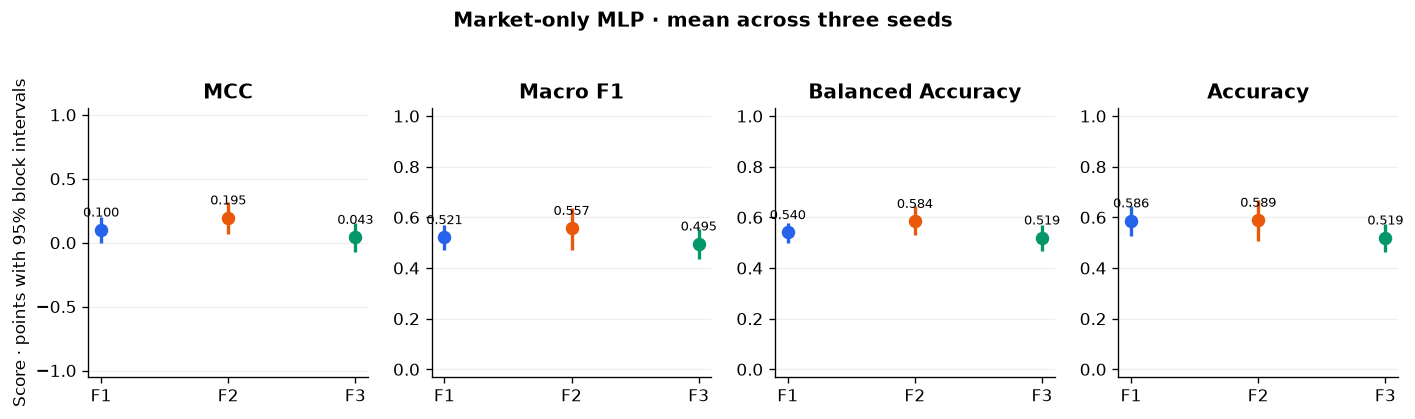

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, metric in zip(axes, ["mcc", "macro_f1", "balanced_accuracy", "accuracy"]):
    for index, row in results.reset_index(drop=True).iterrows():
        bounds = intervals.loc[intervals.run.eq(row["run"]) & intervals.metric.eq(metric)].iloc[0]
        value = row[metric]
        ax.vlines(index, bounds.low_95, bounds.high_95, color=COLORS[index % 3], linewidth=2)
        ax.scatter(index, value, color=COLORS[index % 3], s=50, zorder=3)
        ax.annotate(f"{value:.3f}", (index, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(results)), results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set_title(metric.replace("_", " ").upper() if metric == "mcc" else metric.replace("_", " ").title())
    ax.set_ylim(-1.05, 1.05) if metric == "mcc" else ax.set_ylim(-.03, 1.03)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Score · points with 95% block intervals")
fig.suptitle("Market-only MLP · mean across three seeds", y=1.04, fontweight="bold")
fig.tight_layout()
plt.show()

## Training curves

Solid = validation log loss; dashed = training log loss. Checkpoints are selected by MCC, then macro-F1, then log loss.


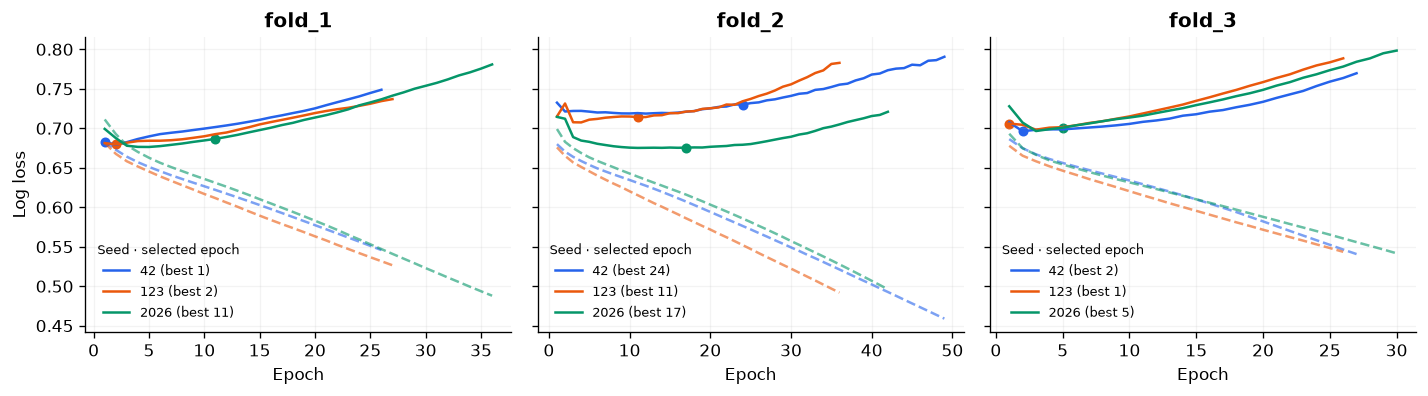

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, run in zip(axes, [f"fold_{i}" for i in sorted(folds.fold.unique())]):
    for index, seed in enumerate(SEEDS):
        curve = history.loc[history.run.eq(run) & history.seed.eq(seed)]
        best_epoch = int(fits.loc[fits.run.eq(run) & fits.seed.eq(seed), "best_epoch"].iloc[0])
        ax.plot(curve.epoch, curve.val_log_loss, color=COLORS[index], label=f"{seed} (best {best_epoch})")
        ax.plot(curve.epoch, curve.train_log_loss, "--", color=COLORS[index], alpha=.6)
        selected = curve.loc[curve.epoch.eq(best_epoch)].iloc[0]
        ax.scatter([best_epoch], [selected.val_log_loss], s=25, color=COLORS[index])
    ax.set(title=run, xlabel="Epoch")
    ax.grid(alpha=.15)
    ax.legend(title="Seed · selected epoch", fontsize=8, title_fontsize=8, frameon=False)
axes[0].set_ylabel("Log loss")
fig.tight_layout()
plt.show()

## Classes, confusion, and probability quality

Confusion annotations are mean counts across three seeds and row percentages. Each fold still has the same unique evaluation dates. Per-class metrics are seed means. Calibration pools seed predictions within bins, so its counts include repeated dates; it is not an ensemble or an independent-sample count.

,run,class,support,precision,recall,f1
0,fold_1,DOWN,64,0.5087,0.2969,0.3514
1,fold_1,UP,94,0.6220,0.7837,0.6898
2,fold_2,DOWN,78,0.6597,0.3291,0.4381
3,fold_2,UP,81,0.5658,0.8395,0.6758
4,fold_3,DOWN,79,0.5353,0.3038,0.3868
5,fold_3,UP,79,0.5131,0.7342,0.6038


,run,bin,prediction_entries,unique_dates,predicted_up,observed_up
0,fold_1,3,4,4,0.3847,0.7500
1,fold_1,4,114,84,0.4685,0.5088
2,fold_1,5,236,139,0.5471,0.6271
3,fold_1,6,87,65,0.6390,0.5517
4,fold_1,7,26,23,0.7468,0.8077
5,fold_1,8,6,5,0.8604,0.6667
6,fold_1,9,1,1,0.9595,0.0000
7,fold_2,1,1,1,0.1168,0.0000
8,fold_2,2,10,6,0.2526,0.0000
9,fold_2,3,24,20,0.3635,0.3333


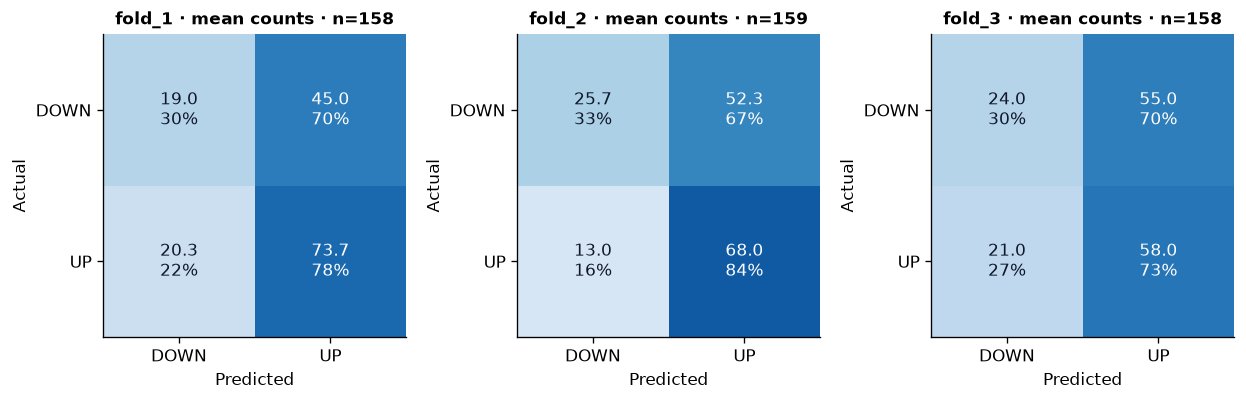

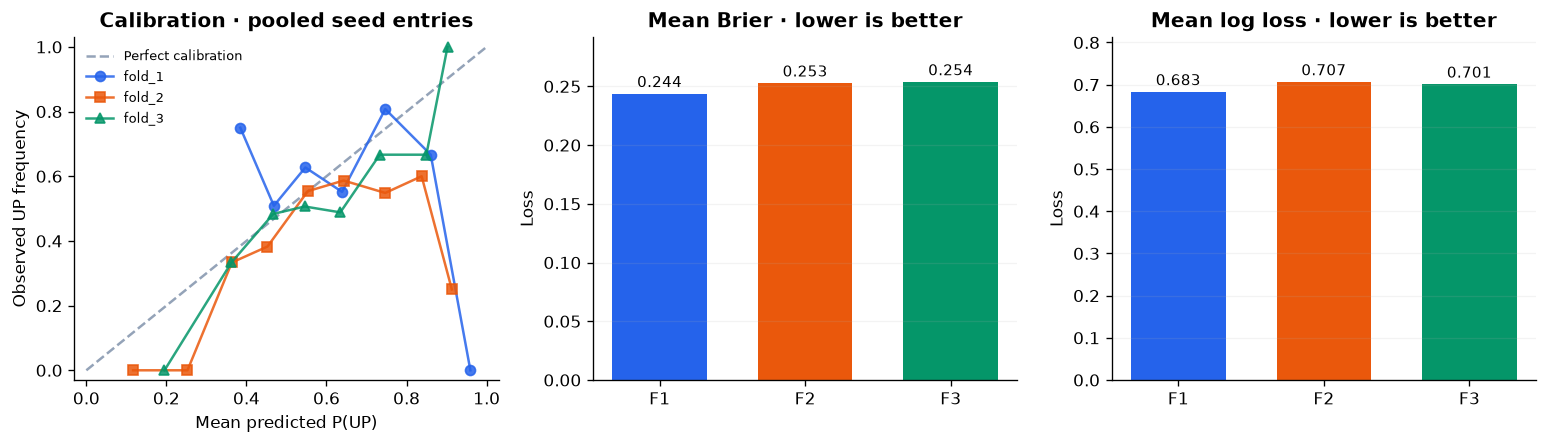

In [9]:
class_rows, calibration_rows = [], []
for row in results.to_dict("records"):
    for label, suffix in [("DOWN", "down"), ("UP", "up")]:
        class_rows.append({"run": row["run"], "class": label, "support": row[f"n_{suffix}"],
                           "precision": row[f"precision_{suffix}"], "recall": row[f"recall_{suffix}"], "f1": row[f"f1_{suffix}"]})
for run, frame in predictions.groupby("run", sort=False):
    bin_ids = np.minimum((frame.p_up.to_numpy() * 10).astype(int), 9)
    for bin_id in np.unique(bin_ids):
        group = frame.loc[bin_ids == bin_id]
        calibration_rows.append({"run": run, "bin": int(bin_id), "prediction_entries": len(group),
                                 "unique_dates": group.Date.nunique(), "predicted_up": float(group.p_up.mean()),
                                 "observed_up": float(group.y.mean())})
per_class, calibration = pd.DataFrame(class_rows), pd.DataFrame(calibration_rows)
display(per_class.round(4))
display(calibration.round(4))

fig, axes = plt.subplots(1, len(results), figsize=(3.5 * len(results), 3.3), squeeze=False)
for ax, row in zip(axes.ravel(), results.to_dict("records")):
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for actual in range(2):
        for predicted in range(2):
            ax.text(predicted, actual, f"{matrix[actual, predicted]:.1f}\n{normalized[actual, predicted]:.0%}",
                    ha="center", va="center", color="white" if normalized[actual, predicted] > .6 else "#0f172a")
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{row['run']} · mean counts · n={row['n']}", fontsize=10)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")
for index, (run, frame) in enumerate(calibration.groupby("run", sort=False)):
    frame = frame.sort_values("predicted_up")
    axes[0].plot(frame.predicted_up, frame.observed_up, marker=["o", "s", "^"][index % 3],
                 color=COLORS[index % 3], alpha=.85, label=run)
axes[0].set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean predicted P(UP)",
            ylabel="Observed UP frequency", title="Calibration · pooled seed entries")
axes[0].legend(fontsize=8, frameon=False)
x = np.arange(len(results))
for ax, metric, title in [(axes[1], "brier", "Mean Brier · lower is better"),
                           (axes[2], "log_loss", "Mean log loss · lower is better")]:
    ax.bar(x, results[metric], color=[COLORS[i % 3] for i in x], width=.65)
    ax.set_xticks(x, results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set(title=title, ylabel="Loss", ylim=(0, max(float(results[metric].max()) * 1.15, .01)))
    for i, value in enumerate(results[metric]):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Coverage and subgroup checks

Retain all eligible dates, including empty-news windows. Subgroup sizes count unique dates; scores average individual seeds. Weekday/gap groups use the target endpoint. Inspect small subsets cautiously.

,run,group,n,mcc,macro_f1,balanced_accuracy,accuracy
0,fold_1,all,158,0.0998,0.5206,0.5403,0.5865
1,fold_1,news_present,21,-0.0241,0.4688,0.4907,0.5238
2,fold_1,empty,137,0.1213,0.5288,0.5479,0.5961
3,fold_1,singleton,13,0.1070,0.5329,0.5417,0.5897
4,fold_1,multi_article,8,-0.2121,0.3682,0.4167,0.4167
5,fold_1,target_Monday,30,-0.1420,0.3750,0.4570,0.5111
6,fold_1,target_other_weekday,128,0.1501,0.5465,0.5629,0.6042
7,fold_1,target_gap_1d,122,0.1442,0.5440,0.5612,0.6038
8,fold_1,target_gap_3d,28,-0.1245,0.3832,0.4653,0.5238
9,fold_1,target_gap_other,8,0.1659,0.4975,0.5417,0.5417


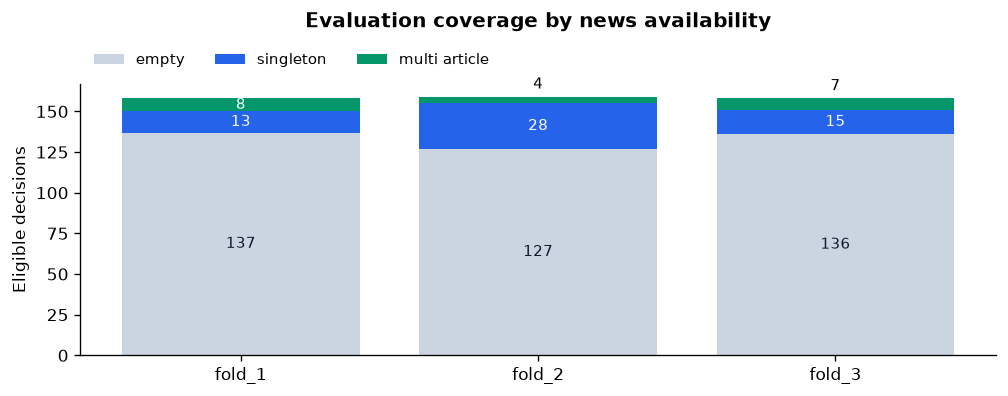

In [10]:
subgroup_rows = []
for run, all_seeds in predictions.groupby("run", sort=False):
    frame = all_seeds.loc[all_seeds.training_seed.eq(SEEDS[0])].sort_values("Date")
    masks = {"all": np.ones(len(frame), dtype=bool), "news_present": frame.n_berita.gt(0),
             "empty": frame.n_berita.eq(0), "singleton": frame.n_berita.eq(1),
             "multi_article": frame.n_berita.gt(1), "target_Monday": frame.target_weekday.eq(0),
             "target_other_weekday": frame.target_weekday.ne(0), "target_gap_1d": frame.realized_target_gap_days.eq(1),
             "target_gap_3d": frame.realized_target_gap_days.eq(3),
             "target_gap_other": ~frame.realized_target_gap_days.isin([1, 3])}
    for name, mask in masks.items():
        dates = frame.loc[mask, "Date"]
        selected = all_seeds.loc[all_seeds.Date.isin(dates)]
        if len(dates):
            scores = pd.DataFrame([score_binary(g.y, g.p_up) for _, g in selected.groupby("training_seed")]).mean().to_dict()
        else:
            scores = {m: np.nan for m in METRICS}
        subgroup_rows.append({"run": run, "group": name, **scores, "n": len(dates)})
subgroups = pd.DataFrame(subgroup_rows)
display(subgroups[["run", "group", "n", "mcc", "macro_f1", "balanced_accuracy", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
coverage = subgroups.loc[subgroups.group.isin(["empty", "singleton", "multi_article"])].pivot(index="run", columns="group", values="n")
coverage = coverage.reindex(results.run)
bottom = np.zeros(len(coverage))
for group, color in [("empty", "#cbd5e1"), ("singleton", COLORS[0]), ("multi_article", COLORS[2])]:
    values = coverage[group].to_numpy()
    ax.bar(coverage.index, values, bottom=bottom, color=color, label=group.replace("_", " "))
    for index, (base, value) in enumerate(zip(bottom, values)):
        if value >= 8:
            ax.text(index, base + value / 2, str(int(value)), ha="center", va="center", fontsize=9,
                    color="#0f172a" if group == "empty" else "white")
        elif value:
            ax.annotate(str(int(value)), (index, base + value), xytext=(0, 5),
                        textcoords="offset points", ha="center", fontsize=9)
    bottom += values
ax.set_ylabel("Eligible decisions")
ax.set_title("Evaluation coverage by news availability", pad=34)
ax.legend(frameon=False, ncol=3, bbox_to_anchor=(0, 1.01), loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## Result bundle

The expandable JSON stores per-seed/fold metrics, sampling intervals, predictions, training history, selected weights/scalers, and source hashes. No sidecar files are written. Keep the classifier family and training budget consistent in the next Level 1 conditions; add text/availability only where their condition allows it.

In [11]:
files = [BASE / name for name in ["fold_manifest.csv", "final_fit_manifest.csv", "calendar_partitions.csv",
                                  "daily_market.csv", "pipeline_manifest.json", "feature_contract.json"]]
run_metadata = {
    "model_id": MODEL_ID, "condition": "market_only", "run_at_wib": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "final_test_evaluated": RUN_FINAL_TEST, "hard_prediction_rule": "P(UP) >= 0.5; threshold fixed",
    "probability_rule": "MLP logistic output; no calibration fitted",
    "input_predictors": FEATURES, "excluded_predictors": ["news content", "n_berita", "has_news", "future outcomes"],
    "macro_inputs": [], "training_seeds": SEEDS, "threshold_tuned": False,
    "model": MLP_CONFIG, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "selection": ["validation MCC", "validation macro-F1", "negative validation log loss"],
    "scaler_fit": "Per training split only", "final_epochs": "Per-seed median best epoch across development folds",
    "trainable_parameters_per_fit": sorted(fits.trainable_parameters.unique().tolist()),
    "score_aggregation": "Mean individual-seed scores within fold, then equal-weight mean across validation folds; no ensemble",
    "bootstrap": {"method": "circular moving blocks", "repeats": BOOTSTRAP_REPEATS,
                  "block_length_evaluated_observations": BLOCK_LENGTH, "base_seed": BOOTSTRAP_SEED,
                  "run_seed_rule": "base_seed + 1-based run index in results", "confidence": .95,
                  "same_sampled_dates_across_training_seeds": True, "conditional_on_fixed_predictions": True},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__, "sklearn": sklearn.__version__},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in files},
    "source_sha256": pipeline["input_sha256"], "alignment_mode": pipeline["config"]["alignment_mode"],
    "geopolitical_policy": pipeline["config"]["geopolitical_policy"],
}
to_records = lambda frame: json.loads(frame.to_json(orient="records", date_format="iso"))
result_bundle = {"metadata": run_metadata, "fits": to_records(fits), "metrics": to_records(results),
                 "seed_metrics": to_records(seed_results), "seed_std": to_records(seed_std.reset_index()),
                 "validation_summary": to_records(validation_results.agg(["mean", "std"]).rename_axis("statistic").reset_index()),
                 "intervals": to_records(intervals), "per_class": to_records(per_class), "calibration": to_records(calibration),
                 "subgroups": to_records(subgroups), "predictions": to_records(predictions),
                 "history": to_records(history), "selected_models": snapshots}
json.dumps(result_bundle, allow_nan=False)
display({"application/json": result_bundle}, raw=True, metadata={"application/json": {"expanded": False}})
print(f"Stored {len(predictions)} seed-specific predictions across {predictions.Date.nunique()} dates; final test evaluated: {RUN_FINAL_TEST}.")

Stored 1425 seed-specific predictions across 475 dates; final test evaluated: False.
